# Temporal 1D CNN, Stacked Ensemble and Explainability

This notebook extends the advanced crop-yield experiment with three additions:

1. **A temporal 1D CNN.** The data is a table, so an image CNN has nothing to work on. Each country-crop pair, however, is a yearly time series. The CNN reads the previous five years of yield, rainfall, pesticide use and temperature, adds this year's weather and pesticide values, and predicts this year's yield. Country and crop enter as learned embeddings.
2. **Ensembles.** A simple average, a validation-weighted average and a stacked ensemble combine Extra Trees, Gradient Boosting, the MLP and the CNN.
3. **Explainability.** Grad-CAM and Integrated Gradients explain the CNN. SHAP explains Extra Trees and the stacked ensemble.

**Fair comparison.** The CNN sees past yields, which the earlier models did not. Every tree and neural model in this notebook therefore receives the same five years of lagged features. A plain "last year's yield" baseline is included, because past yield alone is a strong predictor.

**Time-based split (same as the project):**

| Phase | Train | Evaluate | Used for |
|---|---|---|---|
| Selection | target years 1995–2005 | 2006–2009 | model choice and ensemble weights |
| Final | target years 1995–2009 | 2010–2013 | reported test scores only |

The 2010–2013 test years never influence a model choice or an ensemble weight.

## 1. Imports and settings

In [1]:
from pathlib import Path
from time import perf_counter
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import torch
import torch.nn as nn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(8)

TARGET = "hg/ha_yield"
WEATHER = ["average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
WINDOW = 5                       # number of past years the CNN reads
SHORT = ["yield", "rain", "pesticides", "temp"]   # names of the four time-series channels
COLORS = ["#0b4650", "#d2a33a", "#4f8a54", "#d18445", "#66777a", "#165b65", "#a47717", "#8fb3b8", "#c75d4a"]
sns.set_theme(style="whitegrid")
print("torch", torch.__version__, "| shap", shap.__version__)

torch 2.5.1+cu121 | shap 0.51.0


## 2. Remove duplicate country-crop-year rows

`yield_df.csv` repeats many country-crop-year combinations. Inside each repeated group the yield, rainfall and pesticide values are identical and only `avg_temp` changes. This is consistent with several temperature stations per country being merged into the table. Large countries such as India are repeated most, so they would be over-weighted. Copies of one row could also land on both sides of a random split.

We keep **one row per country-crop-year** and average the temperatures.

,value
rows in yield_df.csv,28242
unique country-crop-year rows,13130
groups with repeats,3837
largest repeat count,22
groups where yield differs,0
groups where rainfall differs,0
groups where pesticides differ,0
groups where temperature differs,3690


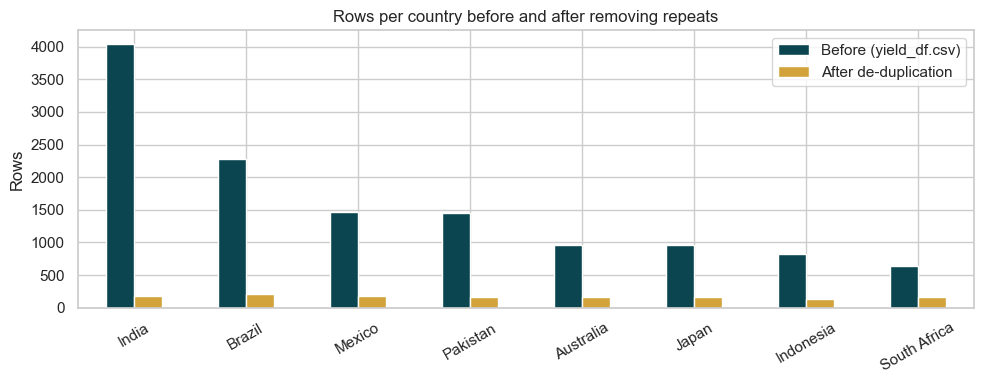

In [2]:
raw = pd.read_csv("dataset/yield_df.csv").drop(columns=["Unnamed: 0"], errors="ignore")
keys = ["Area", "Item", "Year"]

groups = raw.groupby(keys)
check = pd.Series({
    "rows in yield_df.csv": len(raw),
    "unique country-crop-year rows": groups.ngroups,
    "groups with repeats": int((groups.size() > 1).sum()),
    "largest repeat count": int(groups.size().max()),
    "groups where yield differs": int((groups[TARGET].nunique() > 1).sum()),
    "groups where rainfall differs": int((groups["average_rain_fall_mm_per_year"].nunique() > 1).sum()),
    "groups where pesticides differ": int((groups["pesticides_tonnes"].nunique() > 1).sum()),
    "groups where temperature differs": int((groups["avg_temp"].nunique() > 1).sum()),
})
display(check.to_frame("value"))
assert check["groups where yield differs"] == 0, "Repeated rows disagree on yield"

data = groups.agg({TARGET: "first", "average_rain_fall_mm_per_year": "first",
                   "pesticides_tonnes": "first", "avg_temp": "mean"}).reset_index()

before = raw.Area.value_counts().head(8)
after = data.Area.value_counts().reindex(before.index)
fig, ax = plt.subplots(figsize=(10, 4))
pd.DataFrame({"Before (yield_df.csv)": before, "After de-duplication": after}).plot.bar(
    ax=ax, color=COLORS[:2], rot=30)
ax.set(title="Rows per country before and after removing repeats", ylabel="Rows", xlabel="")
plt.tight_layout(); plt.show()

## 3. Fill the missing year and build five-year windows

The dataset has **no rows for 2003**. Without a fix, most windows that span 2003 would be lost. For each country-crop pair we insert 2003 and linearly interpolate it from 2002 and 2004. Only single-year gaps between two real years are filled.

Interpolated years are used **only as past inputs**. They are never prediction targets and never count in any score.

Each sample contains:
- **Past years (t−5 … t−1):** yield, rainfall, pesticides and temperature (`yield_lag1` is last year's yield).
- **Current year t:** rainfall, pesticides and temperature (the scenario inputs), plus the year number, country and crop.
- **Target:** the real yield in year t.

In [3]:
def complete_years(frame):
    pieces = []
    for (area, item), g in frame.groupby(["Area", "Item"], sort=True):
        g = g.set_index("Year").reindex(range(g.Year.min(), g.Year.max() + 1))
        g["observed"] = g[TARGET].notna()
        cols = [TARGET] + WEATHER
        g[cols] = g[cols].interpolate(method="linear", limit=1, limit_area="inside")
        g["Area"], g["Item"] = area, item
        pieces.append(g.rename_axis("Year").reset_index())
    return pd.concat(pieces, ignore_index=True)


def build_samples(full, window=WINDOW):
    rows = []
    channels = [TARGET] + WEATHER
    for (area, item), g in full.groupby(["Area", "Item"], sort=True):
        g = g.sort_values("Year").reset_index(drop=True)
        values = g[channels].to_numpy(float)
        for i in range(window, len(g)):
            if not g.at[i, "observed"]:
                continue
            past = values[i - window:i]
            if np.isnan(past).any():
                continue
            row = {"Area": area, "Item": item, "Year": int(g.at[i, "Year"]), TARGET: g.at[i, TARGET]}
            for col in WEATHER:
                row[col] = g.at[i, col]
            for lag in range(1, window + 1):
                for c, name in enumerate(SHORT):
                    row[f"{name}_lag{lag}"] = past[window - lag, c]
            rows.append(row)
    return pd.DataFrame(rows)


full_years = complete_years(data)
samples = build_samples(full_years)

LAG_FEATURES = [f"{n}_lag{lag}" for lag in range(1, WINDOW + 1) for n in SHORT]
FEATURES = ["Area", "Item", "Year"] + WEATHER + LAG_FEATURES
NO_LAG_FEATURES = ["Area", "Item", "Year"] + WEATHER
LAG_COLUMNS = [[f"{n}_lag{lag}" for n in SHORT] for lag in range(WINDOW, 0, -1)]  # oldest year first

selection_train = samples.Year <= 2005
validation = samples.Year.between(2006, 2009)
full_train = samples.Year <= 2009
test = samples.Year >= 2010

print(f"Interpolated rows inserted: {(~full_years.observed).sum():,}")
print(f"Five-year samples: {len(samples):,} from {samples.groupby(['Area','Item']).ngroups} country-crop pairs")
for label, mask in [("selection train", selection_train), ("validation", validation),
                    ("final train", full_train), ("test", test)]:
    years = samples.loc[mask, "Year"]
    print(f"  {label:<16} {years.min()}-{years.max()}  {mask.sum():>5,} samples")
samples.head(3)

Interpolated rows inserted: 604
Five-year samples: 10,161 from 585 country-crop pairs
  selection train  1995-2005  5,549 samples
  validation       2006-2009  2,292 samples
  final train      1995-2009  7,841 samples
  test             2010-2013  2,320 samples


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,yield_lag1,rain_lag1,pesticides_lag1,...,pesticides_lag3,temp_lag3,yield_lag4,rain_lag4,pesticides_lag4,temp_lag4,yield_lag5,rain_lag5,pesticides_lag5,temp_lag5
0,Albania,Maize,1995,31300.0,1485.0,251.00,15.67,25848.0,1485.0,201.00,...,121.0,16.06,29068.0,1485.0,121.0,15.36,36613.0,1485.0,121.0,16.37
1,Albania,Maize,1996,32604.0,1485.0,313.96,15.64,31300.0,1485.0,251.00,...,121.0,16.05,24876.0,1485.0,121.0,16.06,29068.0,1485.0,121.0,15.36
2,Albania,Maize,1997,31862.0,1485.0,376.93,15.90,32604.0,1485.0,313.96,...,201.0,16.96,24185.0,1485.0,121.0,16.05,24876.0,1485.0,121.0,16.06


## 4. Models

All models receive the same rows. Every model except the no-lag reference also receives the same lagged features.

| Model | Inputs | Notes |
|---|---|---|
| Last year's yield | `yield_lag1` | naive baseline with no learning |
| Extra Trees (no lags) | the project's original six features | shows how much the lags add |
| Extra Trees | all features | the project's settings |
| Gradient Boosting | all features | histogram gradient boosting |
| Neural Network (MLP) | all features | 128-64-32 network, standard-scaled target |
| Temporal 1D CNN | all features, reshaped into a 5-year sequence | two convolution layers + embeddings |

**Inside the CNN.** The five past years form a sequence with four channels: log yield, rainfall, log pesticides and temperature. Two `Conv1d` layers (kernel size 3) slide along that sequence. Their output is averaged over time and joined with a country embedding (12 numbers), a crop embedding (4 numbers) and the current-year inputs. A small dense head then predicts the **change from last year's log yield**, which is added back to last year's value.

Five separate networks are trained with different random seeds and their predictions are averaged. The number of training epochs is chosen by early stopping on the last two years inside each training window. The model is then retrained on the whole window, so validation and test years never steer training.

In [4]:
def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}


def tree_pipeline(features, model):
    numeric = [c for c in features if c not in ("Area", "Item")]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Area", "Item"]),
        ("num", "passthrough", numeric)])
    return Pipeline([("prep", prep), ("model", model)])


def mlp_pipeline(features):
    numeric = [c for c in features if c not in ("Area", "Item")]
    logged = [c for c in numeric if c.startswith(("yield_", "pesticides"))]
    plain = [c for c in numeric if c not in logged]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Area", "Item"]),
        ("log", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), logged),
        ("num", StandardScaler(), plain)])
    network = MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation="relu", solver="adam",
                           batch_size=256, learning_rate_init=0.001, early_stopping=True,
                           validation_fraction=0.15, n_iter_no_change=20, max_iter=300,
                           random_state=SEED)
    # Standard-scaled target, as in the project. A log target made this network overshoot badly.
    model = TransformedTargetRegressor(regressor=network, transformer=StandardScaler())
    return Pipeline([("prep", prep), ("model", model)])

In [5]:
class TemporalCNN(nn.Module):
    def __init__(self, n_areas, n_items, n_channels=4, n_current=4, filters=32):
        super().__init__()
        self.area_embedding = nn.Embedding(n_areas + 1, 12)   # index 0 = unseen country
        self.item_embedding = nn.Embedding(n_items + 1, 4)
        self.conv1 = nn.Conv1d(n_channels, filters, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(filters, filters, kernel_size=3, padding=1)
        self.act = nn.ReLU()
        self.head = nn.Sequential(nn.Linear(filters + 12 + 4 + n_current, 64), nn.ReLU(),
                                  nn.Dropout(0.1), nn.Linear(64, 1))

    def forward(self, seq, current, area, item, return_maps=False):
        maps = self.act(self.conv2(self.act(self.conv1(seq))))   # (batch, filters, years)
        x = torch.cat([maps.mean(dim=2), self.area_embedding(area),
                       self.item_embedding(item), current], dim=1)
        out = seq[:, 0, -1] + self.head(x).squeeze(1)              # last year's yield + learned change
        return (out, maps) if return_maps else out


class CNNRegressor:
    # scikit-learn style wrapper: fit(frame, y) and predict(frame) on the FEATURES table.

    def __init__(self, seeds=(0, 1, 2, 3, 4), max_epochs=300, patience=25, lr=1e-3,
                 batch_size=128, weight_decay=1e-4):
        self.seeds, self.max_epochs, self.patience = seeds, max_epochs, patience
        self.lr, self.batch_size, self.weight_decay = lr, batch_size, weight_decay

    @staticmethod
    def _raw_sequence(frame):
        seq = np.stack([frame[cols].to_numpy(float) for cols in LAG_COLUMNS], axis=2)  # (N, 4, years)
        seq[:, [0, 2], :] = np.log1p(seq[:, [0, 2], :])
        return seq

    @staticmethod
    def _raw_current(frame):
        return np.column_stack([frame["average_rain_fall_mm_per_year"], np.log1p(frame["pesticides_tonnes"]),
                                frame["avg_temp"], frame["Year"]]).astype(float)

    def _tensors(self, frame):
        seq = (self._raw_sequence(frame) - self.seq_mean_[None, :, None]) / self.seq_std_[None, :, None]
        cur = (self._raw_current(frame) - self.cur_mean_) / self.cur_std_
        area = frame["Area"].map(self.areas_).fillna(0).astype(int).to_numpy()
        item = frame["Item"].map(self.items_).fillna(0).astype(int).to_numpy()
        return (torch.tensor(seq, dtype=torch.float32), torch.tensor(cur, dtype=torch.float32),
                torch.tensor(area, dtype=torch.long), torch.tensor(item, dtype=torch.long))

    def _train(self, tensors, target, epochs, seed, val=None):
        torch.manual_seed(seed)
        rng = np.random.default_rng(seed)
        net = TemporalCNN(len(self.areas_), len(self.items_))
        opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        best_loss, best_epoch, history = np.inf, 1, []
        for epoch in range(1, epochs + 1):
            net.train()
            order = rng.permutation(len(target))
            for start in range(0, len(order), self.batch_size):
                idx = torch.as_tensor(order[start:start + self.batch_size])
                opt.zero_grad()
                loss = ((net(*(t[idx] for t in tensors)) - target[idx]) ** 2).mean()
                loss.backward()
                opt.step()
            if val is not None:
                net.eval()
                with torch.no_grad():
                    val_loss = ((net(*val[0]) - val[1]) ** 2).mean().item()
                history.append(val_loss)
                if val_loss < best_loss:
                    best_loss, best_epoch = val_loss, epoch
                elif epoch - best_epoch >= self.patience:
                    break
        return net, best_epoch, history

    def fit(self, frame, y):
        frame = frame.reset_index(drop=True)
        y = np.asarray(y, float)
        self.areas_ = {a: i + 1 for i, a in enumerate(sorted(frame.Area.unique()))}
        self.items_ = {a: i + 1 for i, a in enumerate(sorted(frame.Item.unique()))}
        seq, cur = self._raw_sequence(frame), self._raw_current(frame)
        self.seq_mean_, self.seq_std_ = seq.mean(axis=(0, 2)), seq.std(axis=(0, 2))
        self.cur_mean_, self.cur_std_ = cur.mean(axis=0), cur.std(axis=0)
        tensors = self._tensors(frame)
        target = torch.tensor((np.log1p(y) - self.seq_mean_[0]) / self.seq_std_[0], dtype=torch.float32)

        # Early stopping on the last two years inside this training window only.
        holdout = torch.tensor(frame.Year.isin(sorted(frame.Year.unique())[-2:]).to_numpy())
        inner = tuple(t[~holdout] for t in tensors)
        inner_val = (tuple(t[holdout] for t in tensors), target[holdout])
        _, self.best_epoch_, self.history_ = self._train(inner, target[~holdout], self.max_epochs,
                                                         self.seeds[0], val=inner_val)
        self.nets_ = [self._train(tensors, target, self.best_epoch_, s)[0] for s in self.seeds]
        return self

    def predict(self, frame):
        tensors = self._tensors(frame.reset_index(drop=True))
        outputs = []
        with torch.no_grad():
            for net in self.nets_:
                net.eval()
                outputs.append(torch.cat([net(*(t[i:i + 65536] for t in tensors))
                                          for i in range(0, len(tensors[0]), 65536)]).numpy())
        z = np.mean(outputs, axis=0)
        return np.expm1(z * self.seq_std_[0] + self.seq_mean_[0])

In [6]:
def make_models():
    return {
        "Extra Trees (no lags)": (NO_LAG_FEATURES, tree_pipeline(NO_LAG_FEATURES, ExtraTreesRegressor(
            n_estimators=250, max_features=0.8, min_samples_leaf=2, n_jobs=8, random_state=SEED))),
        "Extra Trees": (FEATURES, tree_pipeline(FEATURES, ExtraTreesRegressor(
            n_estimators=250, max_features=0.8, min_samples_leaf=2, n_jobs=8, random_state=SEED))),
        "Gradient Boosting": (FEATURES, tree_pipeline(FEATURES, HistGradientBoostingRegressor(
            learning_rate=0.08, max_iter=250, max_leaf_nodes=31, l2_regularization=1.0, random_state=SEED))),
        "Neural Network (MLP)": (FEATURES, mlp_pipeline(FEATURES)),
        "Temporal 1D CNN": (FEATURES, CNNRegressor()),
    }


def run_phase(train_mask, eval_mask, label):
    predictions, fitted, seconds = {}, {}, {}
    predictions["Last year's yield"] = samples.loc[eval_mask, "yield_lag1"].to_numpy()
    for name, (columns, model) in make_models().items():
        start = perf_counter()
        model.fit(samples.loc[train_mask, columns], samples.loc[train_mask, TARGET])
        predictions[name] = np.asarray(model.predict(samples.loc[eval_mask, columns]), float)
        fitted[name] = (columns, model)
        seconds[name] = perf_counter() - start
        print(f"{label}: {name:<24} {seconds[name]:6.1f} s")
    return predictions, fitted, seconds

## 5. Selection phase: train on 1995–2005, score on 2006–2009

In [7]:
y_val = samples.loc[validation, TARGET].to_numpy()
val_years = samples.loc[validation, "Year"].to_numpy()
val_predictions, _, _ = run_phase(selection_train, validation, "selection")
validation_table = pd.DataFrame({name: scores(y_val, p) for name, p in val_predictions.items()}).T
validation_table.sort_values("RMSE").round(3)

selection: Extra Trees (no lags)       1.6 s


selection: Extra Trees                 2.0 s


selection: Gradient Boosting           1.2 s


selection: Neural Network (MLP)        2.2 s


selection: Temporal 1D CNN            16.1 s


,MAE,RMSE,R2
Extra Trees,6912.026,13939.632,0.972
Last year's yield,6974.006,14657.148,0.970
Temporal 1D CNN,7381.570,14816.736,0.969
Gradient Boosting,7615.474,14919.482,0.968
Neural Network (MLP),9703.455,16911.294,0.959
Extra Trees (no lags),9878.345,20510.735,0.940


## 6. Ensembles: weights come from the validation years only

- **Simple average:** each of the four base models counts equally.
- **Weighted average:** each model's weight is proportional to 1 / validation RMSE.
- **Stacking:** a linear regression with non-negative coefficients and no intercept learns how much to trust each model from its 2006–2009 predictions.

Scoring a weighted or stacked ensemble on the same years it learned from would flatter it. Its validation score therefore uses **leave-one-year-out**: weights are learned on three validation years and tested on the fourth, for each of the four years. The final weights are then learned on all four validation years and applied unchanged to 2010–2013.

In [8]:
BASE_MODELS = ["Extra Trees", "Gradient Boosting", "Neural Network (MLP)", "Temporal 1D CNN"]
P_val = np.column_stack([val_predictions[m] for m in BASE_MODELS])


def equal_weights(P, y):
    return np.full(P.shape[1], 1 / P.shape[1])


def inverse_rmse_weights(P, y):
    w = 1 / np.sqrt(((P - y[:, None]) ** 2).mean(axis=0))
    return w / w.sum()


def stacking_weights(P, y):
    return LinearRegression(positive=True, fit_intercept=False).fit(P, y).coef_


ENSEMBLES = {"Ensemble: simple average": equal_weights,
             "Ensemble: weighted average": inverse_rmse_weights,
             "Ensemble: stacking": stacking_weights}

weights = {}
for name, rule in ENSEMBLES.items():
    held_out = np.empty_like(y_val)
    for year in np.unique(val_years):
        m = val_years == year
        held_out[m] = P_val[m] @ rule(P_val[~m], y_val[~m])
    validation_table.loc[name, ["MAE", "RMSE", "R2"]] = list(scores(y_val, held_out).values())
    weights[name] = rule(P_val, y_val)

weight_table = pd.DataFrame(weights, index=BASE_MODELS).T
display(weight_table.round(3))
validation_table.sort_values("RMSE").round(3)

,Extra Trees,Gradient Boosting,Neural Network (MLP),Temporal 1D CNN
Ensemble: simple average,0.25,0.250,0.250,0.250
Ensemble: weighted average,0.27,0.253,0.223,0.254
Ensemble: stacking,0.68,0.000,0.045,0.277


,MAE,RMSE,R2
Extra Trees,6912.026,13939.632,0.972
Ensemble: weighted average,7091.147,14046.984,0.972
Ensemble: simple average,7135.741,14064.615,0.972
Ensemble: stacking,6936.764,14197.194,0.971
Last year's yield,6974.006,14657.148,0.970
Temporal 1D CNN,7381.570,14816.736,0.969
Gradient Boosting,7615.474,14919.482,0.968
Neural Network (MLP),9703.455,16911.294,0.959
Extra Trees (no lags),9878.345,20510.735,0.940


## 7. Final evaluation: refit on 1995–2009, test on 2010–2013

Every model is refitted on all training years, and each ensemble reuses the weights chosen above. The **selected model** is the one with the lowest validation RMSE. The test table is reported afterwards and does not change that choice.

In [9]:
y_test = samples.loc[test, TARGET].to_numpy()
test_predictions, final_models, train_seconds = run_phase(full_train, test, "final")
P_test = np.column_stack([test_predictions[m] for m in BASE_MODELS])
for name in ENSEMBLES:
    test_predictions[name] = P_test @ weights[name]

results = pd.DataFrame({name: scores(y_test, p) for name, p in test_predictions.items()}).T
results.columns = ["Test MAE", "Test RMSE", "Test R²"]
results.insert(0, "Validation RMSE", validation_table["RMSE"])
results = results.sort_values("Validation RMSE")
selected = results.index[0]
print("Selected by validation RMSE:", selected)
Path("output").mkdir(exist_ok=True)
results.round(3).to_csv("output/temporal_cnn_ensemble_results.csv")
results.round(3)

final: Extra Trees (no lags)       2.0 s


final: Extra Trees                 2.8 s


final: Gradient Boosting           1.4 s


final: Neural Network (MLP)        6.4 s


final: Temporal 1D CNN            31.1 s
Selected by validation RMSE: Extra Trees


,Validation RMSE,Test MAE,Test RMSE,Test R²
Extra Trees,13939.632,7564.940,15683.206,0.968
Ensemble: weighted average,14046.984,7594.922,15590.177,0.968
Ensemble: simple average,14064.615,7633.135,15610.054,0.968
Ensemble: stacking,14197.194,7401.997,15454.882,0.969
Last year's yield,14657.148,7766.018,16738.258,0.964
Temporal 1D CNN,14816.736,8014.704,16647.012,0.964
Gradient Boosting,14919.482,8029.653,16420.802,0.965
Neural Network (MLP),16911.294,9624.132,17669.333,0.959
Extra Trees (no lags),20510.735,10544.429,20941.090,0.943


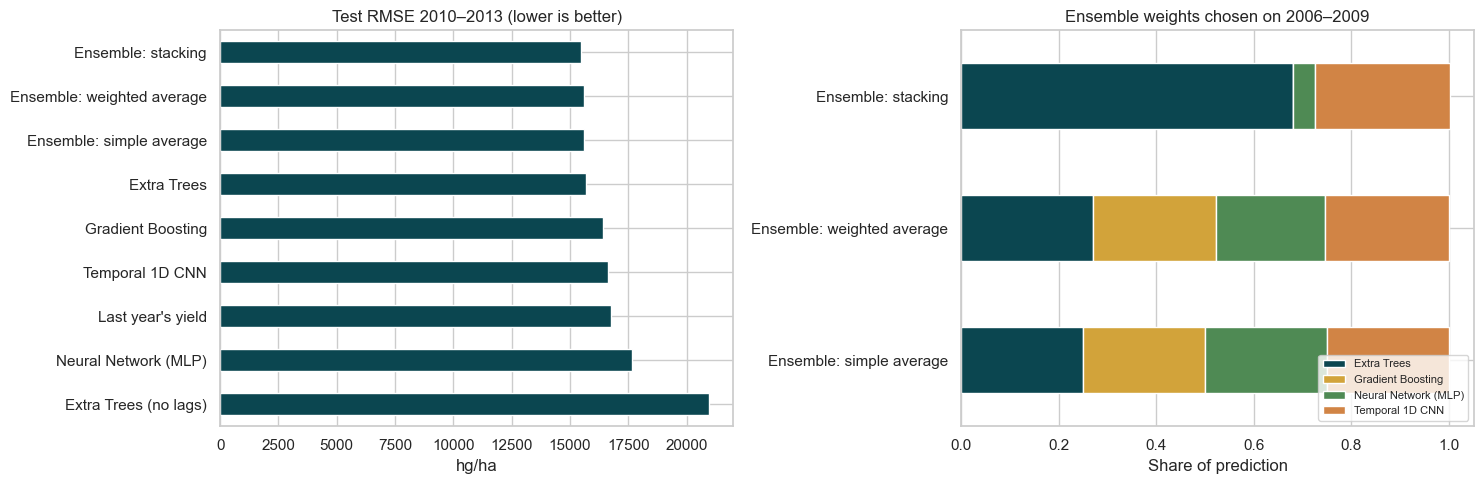

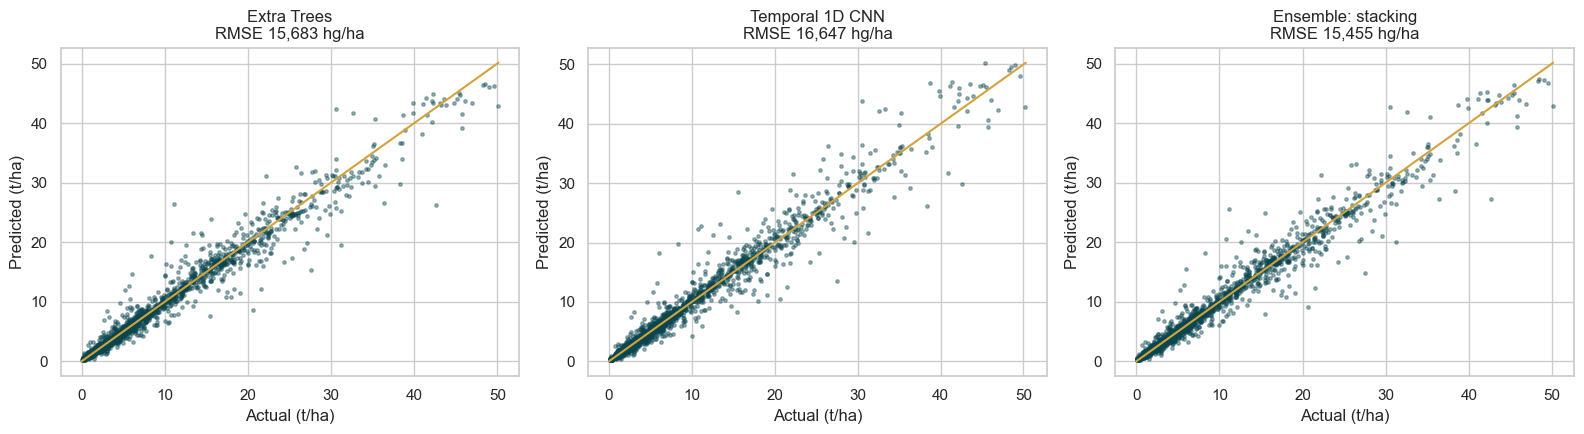

In [10]:
order = results.sort_values("Test RMSE").index
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
results.loc[order, "Test RMSE"].plot.barh(ax=axes[0], color=COLORS[0])
axes[0].invert_yaxis(); axes[0].set(title="Test RMSE 2010–2013 (lower is better)", xlabel="hg/ha", ylabel="")
weight_table.plot.barh(ax=axes[1], color=COLORS[:4], stacked=True)
axes[1].set(title="Ensemble weights chosen on 2006–2009", xlabel="Share of prediction", ylabel="")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, ["Extra Trees", "Temporal 1D CNN", "Ensemble: stacking"]):
    ax.scatter(y_test / 1e4, test_predictions[name] / 1e4, s=6, alpha=0.4, color=COLORS[0])
    top = max(y_test.max(), test_predictions[name].max()) / 1e4
    ax.plot([0, top], [0, top], color=COLORS[1], lw=1.5)
    ax.set(title=f"{name}\nRMSE {results.loc[name, 'Test RMSE']:,.0f} hg/ha",
           xlabel="Actual (t/ha)", ylabel="Predicted (t/ha)")
plt.tight_layout(); plt.show()

### CNN training curve

During early stopping, the CNN's loss on its inner holdout years falls and then levels off. Training stops `patience` epochs after the best epoch, and the networks are retrained for that best number of epochs.

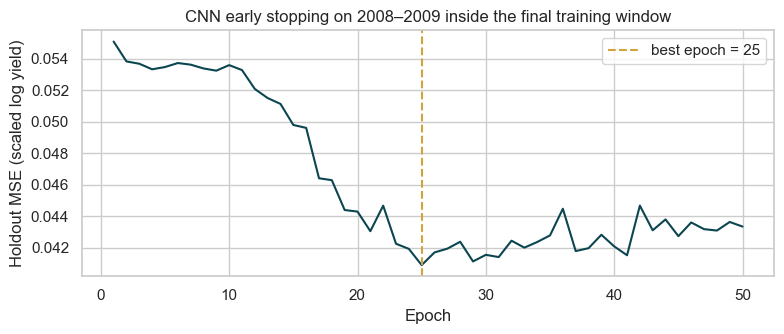

In [11]:
cnn = final_models["Temporal 1D CNN"][1]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, len(cnn.history_) + 1), cnn.history_, color=COLORS[0])
ax.axvline(cnn.best_epoch_, color=COLORS[1], ls="--", label=f"best epoch = {cnn.best_epoch_}")
ax.set(xlabel="Epoch", ylabel="Holdout MSE (scaled log yield)", title="CNN early stopping on 2008–2009 inside the final training window")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Grad-CAM for the CNN: which past years mattered?

Grad-CAM takes the gradient of the prediction with respect to the second convolution layer's output. For each filter it averages that gradient over time to get a weight. The weighted sum of the filter maps (negatives set to zero) gives one importance score for each of the five past years, scaled to 0–1.

One caveat: last year's yield also reaches the output **directly**, through the residual connection, without passing through the convolutions. Grad-CAM only sees the convolution path. Integrated Gradients in the next section covers both paths.

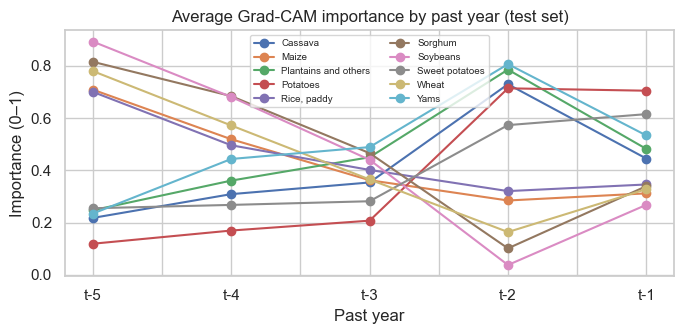

Soybeans, Tajikistan: year 2008 carried the most weight for the 2012 estimate.
Soybeans, Greece: year 2008 carried the most weight for the 2011 estimate.
Sorghum, Kazakhstan: year 2007 carried the most weight for the 2011 estimate.


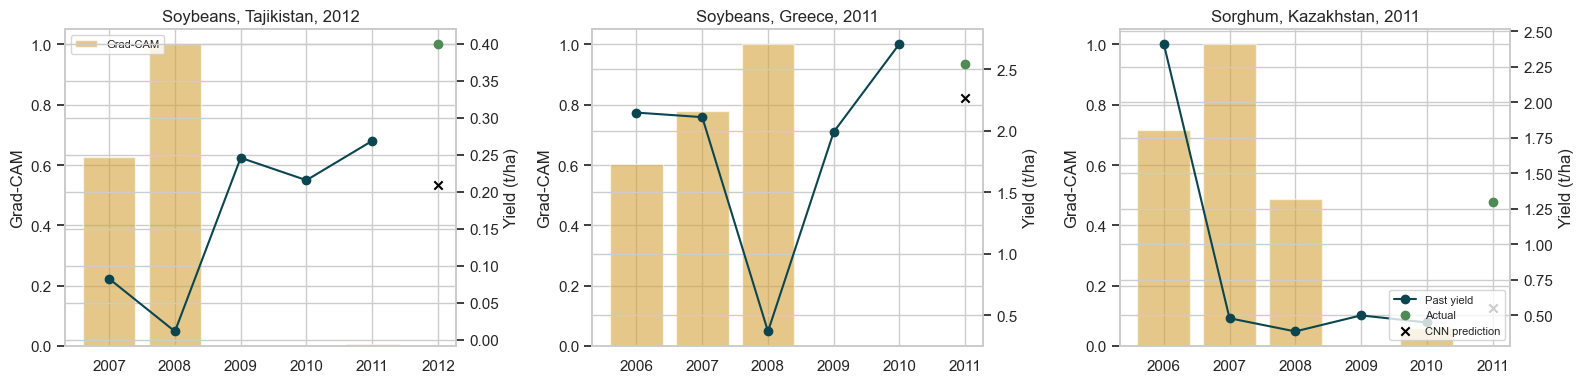

In [12]:
test_frame = samples.loc[test].reset_index(drop=True)


def grad_cam(model, frame):
    seq, cur, area, item = model._tensors(frame.reset_index(drop=True))
    cams = []
    for net in model.nets_:
        net.eval()
        out, maps = net(seq, cur, area, item, return_maps=True)
        grads = torch.autograd.grad(out.sum(), maps)[0]
        cam = torch.relu((grads.mean(dim=2, keepdim=True) * maps).sum(dim=1))
        cams.append(cam.detach().numpy())
    cam = np.mean(cams, axis=0)
    return cam / (cam.max(axis=1, keepdims=True) + 1e-9)


cam = grad_cam(cnn, test_frame)
year_labels = [f"t-{lag}" for lag in range(WINDOW, 0, -1)]

fig, ax = plt.subplots(figsize=(7, 3.5))
pd.DataFrame(cam, columns=year_labels).groupby(test_frame.Item).mean().T.plot(ax=ax, marker="o")
ax.set(title="Average Grad-CAM importance by past year (test set)", ylabel="Importance (0–1)", xlabel="Past year")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

# Three test predictions (from different country-crop pairs) whose history has the sharpest one-year drop.
history = test_frame[[f"yield_lag{lag}" for lag in range(WINDOW, 0, -1)]].to_numpy()
drop = (history[:, :-1] - history[:, 1:]) / history[:, :-1]
ranked = test_frame.assign(drop=drop.max(axis=1)).sort_values("drop", ascending=False)
examples = ranked.drop_duplicates(["Area", "Item"]).index[:3].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, i in zip(axes, examples):
    row = test_frame.iloc[i]
    years = [row.Year - lag for lag in range(WINDOW, 0, -1)]
    ax.bar(years, cam[i], color=COLORS[1], alpha=0.6, label="Grad-CAM")
    ax2 = ax.twinx()
    ax2.plot(years, history[i] / 1e4, marker="o", color=COLORS[0], label="Past yield")
    ax2.scatter([row.Year], [row[TARGET] / 1e4], color=COLORS[2], zorder=3, label="Actual")
    ax2.scatter([row.Year], [test_predictions["Temporal 1D CNN"][i] / 1e4], marker="x",
                color="black", zorder=3, label="CNN prediction")
    ax.set(title=f"{row.Item}, {row.Area}, {row.Year}", ylim=(0, 1.05), ylabel="Grad-CAM")
    ax.set_xticks(years + [row.Year])
    ax2.set_ylabel("Yield (t/ha)")
    top_year = years[int(np.argmax(cam[i]))]
    print(f"{row.Item}, {row.Area}: year {top_year} carried the most weight for the {row.Year} estimate.")
axes[0].legend(loc="upper left", fontsize=8); ax2.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 9. Integrated Gradients for the CNN: which feature in which year?

Integrated Gradients compares each input with a baseline (here: the training average, which is zero after scaling). It adds up the gradients along the straight path from the baseline to the real input. The result splits a prediction into contributions from **each channel in each year**, including the direct shortcut from last year's yield. The heat map shows the average absolute contribution over the test set.

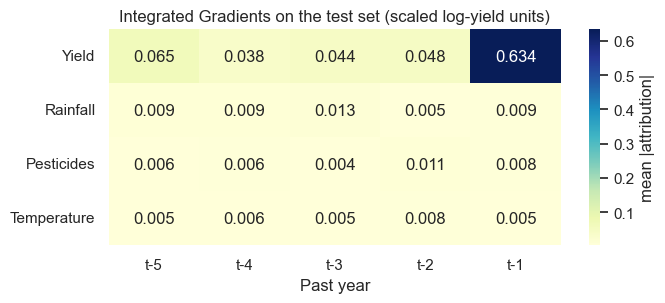

In [13]:
def integrated_gradients(model, frame, steps=40):
    seq, cur, area, item = model._tensors(frame.reset_index(drop=True))
    total = torch.zeros_like(seq)
    for net in model.nets_:
        net.eval()
        for alpha in torch.linspace(0, 1, steps):
            x = (alpha * seq).requires_grad_(True)
            total += torch.autograd.grad(net(x, cur, area, item).sum(), x)[0]
    return (seq * total / (steps * len(model.nets_))).numpy()   # (N, channels, years)


ig = integrated_gradients(cnn, test_frame)
heat = pd.DataFrame(np.abs(ig).mean(axis=0), index=["Yield", "Rainfall", "Pesticides", "Temperature"],
                    columns=year_labels)
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "mean |attribution|"})
ax.set(title="Integrated Gradients on the test set (scaled log-yield units)", xlabel="Past year")
plt.tight_layout(); plt.show()

## 10. SHAP for Extra Trees and for the stacked ensemble

SHAP splits each prediction into feature contributions in **hg/ha**. Positive values push the predicted yield up and negative values push it down. The contributions add up to the gap between that prediction and the average prediction. To keep the charts readable, related columns are grouped: the 100+ one-hot country columns become *Country*, and the five lags of each variable become one *Past …* group.

- **Extra Trees:** `TreeExplainer` computes exact SHAP values from the trees.
- **Stacked ensemble:** it mixes four different model types, so the model-agnostic `PermutationExplainer` is used. It works on the shared feature table with a 40-row background sample from the training years. It is slower, so it explains a random sample of 100 test rows.

In [14]:
GROUP_OF_LAG = {"yield": "Past yields", "rain": "Past rainfall",
                "pesticides": "Past pesticides", "temp": "Past temperature"}
GROUP_OF_CURRENT = {"average_rain_fall_mm_per_year": "Current rainfall",
                    "pesticides_tonnes": "Current pesticides", "avg_temp": "Current temperature",
                    "Year": "Year"}


def group_of(name):
    name = name.split("__", 1)[-1]
    if name.startswith("Area"):
        return "Country"
    if name.startswith("Item"):
        return "Crop"
    if "_lag" in name:
        return GROUP_OF_LAG[name.split("_lag")[0]]
    return GROUP_OF_CURRENT[name]


def grouped(values, names):
    frame = pd.DataFrame(values, columns=names)
    return frame.T.groupby([group_of(n) for n in names]).sum().T


rng = np.random.default_rng(SEED)
explain_rows = test_frame.iloc[np.sort(rng.choice(len(test_frame), 100, replace=False))].reset_index(drop=True)

# Extra Trees: exact Tree SHAP on the one-hot-encoded inputs.
et_columns, et_pipeline = final_models["Extra Trees"]
et_inputs = et_pipeline.named_steps["prep"].transform(explain_rows[et_columns])
et_names = list(et_pipeline.named_steps["prep"].get_feature_names_out())
start = perf_counter()
et_shap = shap.TreeExplainer(et_pipeline.named_steps["model"]).shap_values(et_inputs, check_additivity=False)
print(f"Tree SHAP: {perf_counter() - start:.1f} s")
et_grouped = grouped(et_shap, et_names)

Tree SHAP: 51.1 s


In [15]:
area_codes = sorted(samples.Area.unique())
item_codes = sorted(samples.Item.unique())


def encode(frame):
    X = frame[FEATURES].copy()
    X["Area"] = pd.Categorical(X.Area, categories=area_codes).codes
    X["Item"] = pd.Categorical(X.Item, categories=item_codes).codes
    return X.astype(float).to_numpy()


def decode(array):
    X = pd.DataFrame(array, columns=FEATURES)
    X["Area"] = np.array(area_codes)[X.Area.round().astype(int)]
    X["Item"] = np.array(item_codes)[X.Item.round().astype(int)]
    return X


stack_w = weights["Ensemble: stacking"]


def stacked_predict(array):
    X = decode(array)
    P = np.column_stack([final_models[m][1].predict(X[final_models[m][0]]) for m in BASE_MODELS])
    return P @ stack_w


background = encode(samples.loc[full_train].sample(40, random_state=SEED))
explainer = shap.PermutationExplainer(stacked_predict, shap.maskers.Independent(background, max_samples=40))
start = perf_counter()
ens_explanation = explainer(encode(explain_rows), max_evals=2 * len(FEATURES) + 1, batch_size=100, silent=True)
print(f"Permutation SHAP: {perf_counter() - start:.1f} s")
ens_grouped = grouped(ens_explanation.values, FEATURES)

Permutation SHAP: 34.4 s


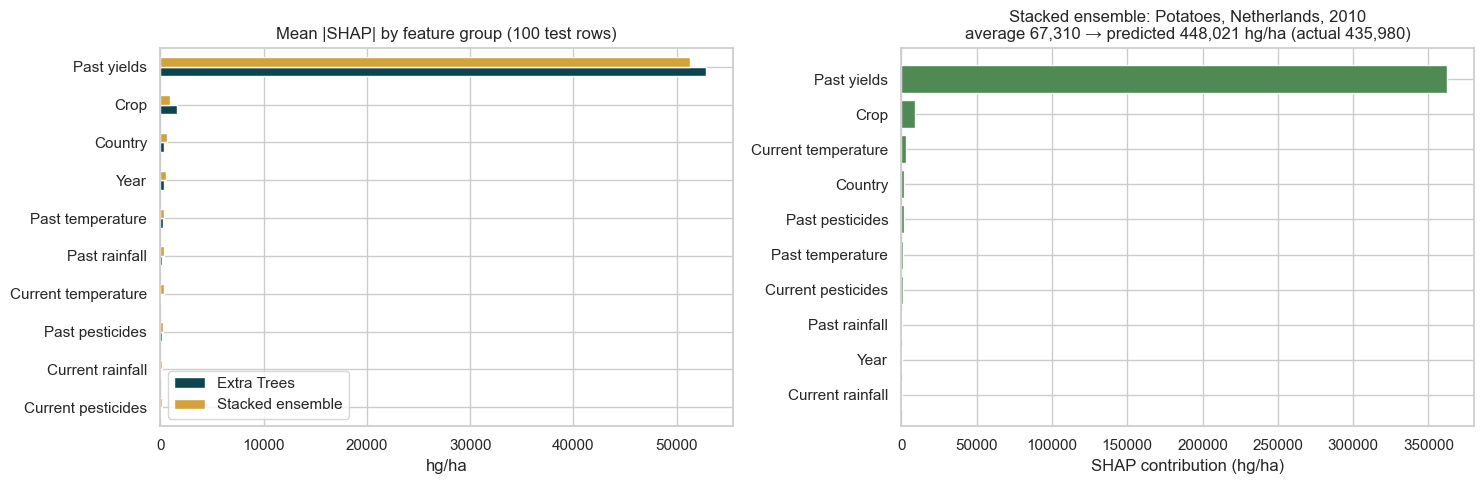

,Extra Trees,Stacked ensemble
Past yields,52820.0,51272.0
Crop,1638.0,959.0
Country,349.0,630.0
Year,372.0,490.0
Past temperature,285.0,340.0
Past rainfall,191.0,334.0
Current temperature,58.0,329.0
Past pesticides,174.0,294.0
Current rainfall,43.0,184.0
Current pesticides,45.0,170.0


In [16]:
importance = pd.DataFrame({"Extra Trees": et_grouped.abs().mean(),
                           "Stacked ensemble": ens_grouped.abs().mean()}).sort_values("Stacked ensemble")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance.plot.barh(ax=axes[0], color=COLORS[:2])
axes[0].set(title="Mean |SHAP| by feature group (100 test rows)", xlabel="hg/ha", ylabel="")

# One prediction explained: how each group moved it away from the average prediction.
i = int(np.argmax(np.abs(ens_grouped.sum(axis=1))))
row = explain_rows.iloc[i]
contrib = ens_grouped.iloc[i].sort_values()
axes[1].barh(contrib.index, contrib.values, color=[COLORS[3] if v < 0 else COLORS[2] for v in contrib.values])
base = float(np.mean(stacked_predict(background)))
axes[1].set(title=f"Stacked ensemble: {row.Item}, {row.Area}, {row.Year}\n"
                  f"average {base:,.0f} → predicted {base + contrib.sum():,.0f} hg/ha (actual {row[TARGET]:,.0f})",
            xlabel="SHAP contribution (hg/ha)")
plt.tight_layout(); plt.show()
importance.sort_values("Stacked ensemble", ascending=False).round(0)

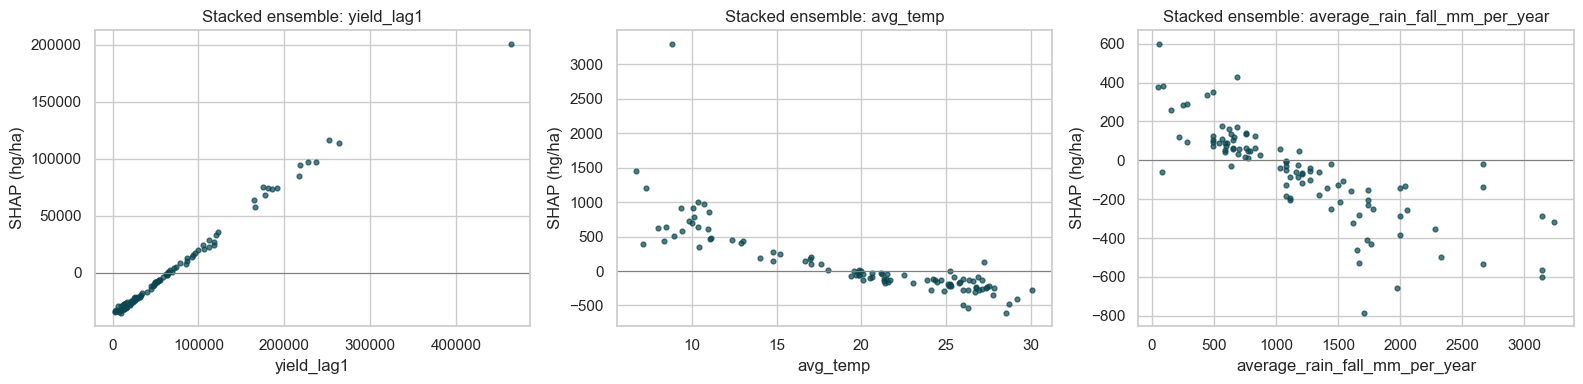

In [17]:
# Direction of the effect: SHAP value against the feature value for three single features.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, ["yield_lag1", "avg_temp", "average_rain_fall_mm_per_year"]):
    j = FEATURES.index(feature)
    ax.scatter(explain_rows[feature], ens_explanation.values[:, j], s=12, color=COLORS[0], alpha=0.7)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=feature, ylabel="SHAP (hg/ha)", title=f"Stacked ensemble: {feature}")
plt.tight_layout(); plt.show()

## 11. Summary for the viva

In [18]:
r = results
best_single = r.loc[[m for m in r.index if not m.startswith("Ensemble")]].sort_values("Test RMSE").index[0]
print(f"Rows after removing repeats: {len(data):,} (from {len(raw):,}); five-year samples: {len(samples):,}")
print(f"Selected by validation RMSE: {selected}  ->  test RMSE {r.loc[selected, 'Test RMSE']:,.0f} hg/ha, R² {r.loc[selected, 'Test R²']:.3f}")
print(f"Best single model on test: {best_single} ({r.loc[best_single, 'Test RMSE']:,.0f} hg/ha)")
baseline_name = "Last year's yield"
print(f"Last-year baseline test RMSE: {r.loc[baseline_name, 'Test RMSE']:,.0f} hg/ha")
print(f"Lags effect, Extra Trees: {r.loc['Extra Trees (no lags)', 'Test RMSE']:,.0f} -> {r.loc['Extra Trees', 'Test RMSE']:,.0f} hg/ha")
print(f"CNN vs Extra Trees (same inputs): {r.loc['Temporal 1D CNN', 'Test RMSE']:,.0f} vs {r.loc['Extra Trees', 'Test RMSE']:,.0f} hg/ha")
print("Stacking weights:", dict(zip(BASE_MODELS, np.round(stack_w, 3))))

Rows after removing repeats: 13,130 (from 28,242); five-year samples: 10,161
Selected by validation RMSE: Extra Trees  ->  test RMSE 15,683 hg/ha, R² 0.968
Best single model on test: Extra Trees (15,683 hg/ha)
Last-year baseline test RMSE: 16,738 hg/ha
Lags effect, Extra Trees: 20,941 -> 15,683 hg/ha
CNN vs Extra Trees (same inputs): 16,647 vs 15,683 hg/ha
Stacking weights: {'Extra Trees': np.float64(0.68), 'Gradient Boosting': np.float64(0.0), 'Neural Network (MLP)': np.float64(0.045), 'Temporal 1D CNN': np.float64(0.277)}


**Points to explain in the viva**

- **Why a 1D CNN and not an image CNN?** A table has no spatial layout, so 2D convolution has nothing to slide over. What the data does have is order in time. The 1D convolution slides along the five past years and learns short patterns such as a drop followed by a recovery.
- **Why give the tree models lag features?** The CNN sees past yields. Without the same lags, any gain could come from the extra information rather than the architecture. The "no lags" row shows how much the lags themselves add.
- **Why remove repeated rows?** Repeated rows give some countries more weight and can leak copies into the test set. The numbers in this notebook therefore do not compare directly with the earlier notebooks.
- **Why a last-year baseline?** Yields change slowly. Any model should beat "same as last year", otherwise it adds nothing.
- **Why leave-one-year-out for the ensemble's validation score?** The stacking weights are learned on 2006–2009, so scoring them on those same years would be optimistic.
- **Grad-CAM vs Integrated Gradients vs SHAP.** Grad-CAM gives one score per past year, but only for the convolution path. Integrated Gradients gives one score per feature per year for the whole CNN. SHAP works for any model, including the trees and the ensemble, and its values are in hg/ha.
- **Limits.** About 7,000 samples is small for deep learning, so the CNN is not expected to dominate the trees. Each fit uses only one test window (2010–2013), and the 2003 values used as inputs are interpolated.